# 04b - Random Forest

Here we train and test Random Forest models on `results/train.csv` (12,378 adults) using the shared 5-fold CV splits. `results/test.csv` is not used.

## 0. Load Data and Check the 5 Folds

First we load `results/train.csv` and check the size and positive rate of each fold.

In [1]:
# load shared modules and training data
import sys
sys.path.append("..")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess
from src.feature_sets import FEATURE_SETS, raw_input_cols

sns.set_theme(style="whitegrid")

df, all_raw_cols = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)

print(f"train shape: {df.shape} | raw features: {len(all_raw_cols)} | positive rate: {y.mean():.4f}")

# check row counts and target balance across folds
fold_rows = []
for i, (tr, va) in enumerate(splits, start=1):
    fold_rows.append({
        "fold": i,
        "train_rows": len(tr),
        "val_rows": len(va),
        "train_pos_rate": round(float(y[tr].mean()), 4),
        "val_pos_rate": round(float(y[va].mean()), 4),
    })

display(pd.DataFrame(fold_rows))

train shape: (12378, 66) | raw features: 63 | positive rate: 0.2961


,fold,train_rows,val_rows,train_pos_rate,val_pos_rate
0,1,9902,2476,0.2961,0.2960
1,2,9902,2476,0.2961,0.2960
2,3,9902,2476,0.2961,0.2960
3,4,9903,2475,0.2961,0.2962
4,5,9903,2475,0.2961,0.2962


**Takeaway:** Each fold trains on about 9,902 rows and validates on about 2,476 rows, and every fold keeps the same 29.6% positive rate.

## 1. Check Feature Sets After Preprocessing

Before training models, we check how many columns Random Forest gets after median imputation, missing flags, and One-Hot encoding.

In [2]:
# check raw, engineered, and preprocessed column counts on fold 1
tr0, _ = splits[0]
prep_rows = []

for name, cols in FEATURE_SETS.items():
    raw_cols = raw_input_cols(cols)
    eng_cols = [c for c in cols if c not in raw_cols]
    prep = preprocess.build_preprocessor("rf", cols, use_engineered=True)
    Xt = prep.fit_transform(df.iloc[tr0][raw_cols])
    prep_rows.append({
        "feature_set": name,
        "n_features": len(cols),
        "raw_cols": len(raw_cols),
        "engineered": ", ".join(eng_cols) if eng_cols else "none",
        "rf_cols_after_prep": Xt.shape[1],
    })

display(pd.DataFrame(prep_rows))

,feature_set,n_features,raw_cols,engineered,rf_cols_after_prep
0,ada_like_7,7,7,none,14
1,custom_10,10,10,none,23
2,no_device_15,15,14,weight_to_highest_ratio,32
3,practical_20,20,19,weight_to_highest_ratio,41
4,top_30,30,29,weight_to_highest_ratio,67
5,all_64,64,63,weight_to_highest_ratio,147


**Takeaway:** Missing flags and One-Hot encoding add extra columns for trees (for example, `practical_20` becomes 41 columns and `all_64` becomes 147 columns).

## 2. Compare the 6 Feature Sets

We run the same baseline Random Forest (`n_estimators=300`, `max_depth=12`, `min_samples_leaf=10`) on all 6 feature sets using the shared 5 folds.

In [3]:
# helper function to run 5-fold CV for Random Forest
def run_rf_cv(cols, params):
    raw_cols = raw_input_cols(cols)
    oof = np.zeros(len(df), dtype=float)
    fold_aucs = []

    for tr, va in splits:
        X_tr, X_va = df.iloc[tr][raw_cols], df.iloc[va][raw_cols]
        prep = preprocess.build_preprocessor("rf", cols, use_engineered=True)
        clf = RandomForestClassifier(**params, n_jobs=-1, random_state=evaluate.SEED)
        pipe = Pipeline([("prep", prep), ("clf", clf)])
        pipe.fit(X_tr, y[tr])
        oof[va] = pipe.predict_proba(X_va)[:, 1]
        fold_aucs.append(round(float(roc_auc_score(y[va], oof[va])), 4))

    _, m = evaluate.find_best_threshold(y, oof)
    m["brier"] = round(float(brier_score_loss(y, oof)), 4)
    return oof, m, fold_aucs

base_params = {"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 10}
fs_rows = []
fold_plot_rows = []

for name, cols in FEATURE_SETS.items():
    _, m, f_aucs = run_rf_cv(cols, base_params)
    print(f"{name:14s} | fold AUCs: {f_aucs} | OOF AUC: {m['roc_auc']:.4f} | F2: {m['f2']:.4f}")
    fs_rows.append({"feature_set": name, "n_features": len(cols), **m})
    for i, a in enumerate(f_aucs, start=1):
        fold_plot_rows.append({"feature_set": name, "fold": f"Fold {i}", "fold_auc": a})

fs_df = pd.DataFrame(fs_rows)
display(fs_df[["feature_set", "n_features", "roc_auc", "pr_auc", "f2", "recall", "specificity", "precision", "threshold", "brier"]])

ada_like_7     | fold AUCs: [0.7392, 0.7554, 0.7372, 0.7381, 0.7219] | OOF AUC: 0.7381 | F2: 0.6006


custom_10      | fold AUCs: [0.7502, 0.761, 0.7445, 0.7527, 0.7355] | OOF AUC: 0.7486 | F2: 0.6186


no_device_15   | fold AUCs: [0.7628, 0.768, 0.7516, 0.7649, 0.7426] | OOF AUC: 0.7577 | F2: 0.6325


practical_20   | fold AUCs: [0.7702, 0.7688, 0.7536, 0.7653, 0.745] | OOF AUC: 0.7603 | F2: 0.6345


top_30         | fold AUCs: [0.7708, 0.7686, 0.7522, 0.7668, 0.743] | OOF AUC: 0.7599 | F2: 0.6349


all_64         | fold AUCs: [0.7678, 0.7606, 0.7513, 0.7642, 0.739] | OOF AUC: 0.7564 | F2: 0.6280


,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,precision,threshold,brier
0,ada_like_7,7,0.7381,0.4981,0.6006,0.6431,0.7011,0.4751,0.356,0.1788
1,custom_10,10,0.7486,0.5193,0.6186,0.6649,0.7016,0.4838,0.341,0.1768
2,no_device_15,15,0.7577,0.5382,0.6325,0.6824,0.7003,0.4892,0.343,0.1738
3,practical_20,20,0.7603,0.5413,0.6345,0.6849,0.7006,0.4903,0.344,0.1730
4,top_30,30,0.7599,0.5395,0.6349,0.6849,0.7019,0.4915,0.347,0.1734
5,all_64,64,0.7564,0.5379,0.6280,0.6767,0.7010,0.4877,0.350,0.1748


**Takeaway:** `practical_20` gets the best ROC-AUC (0.7603), PR-AUC (0.5413), and Brier score (0.1730), while `top_30` gets a slightly higher F2 (0.6349). Using `all_64` drops ROC-AUC to 0.7564 because weak columns add noise when trees sample random features.

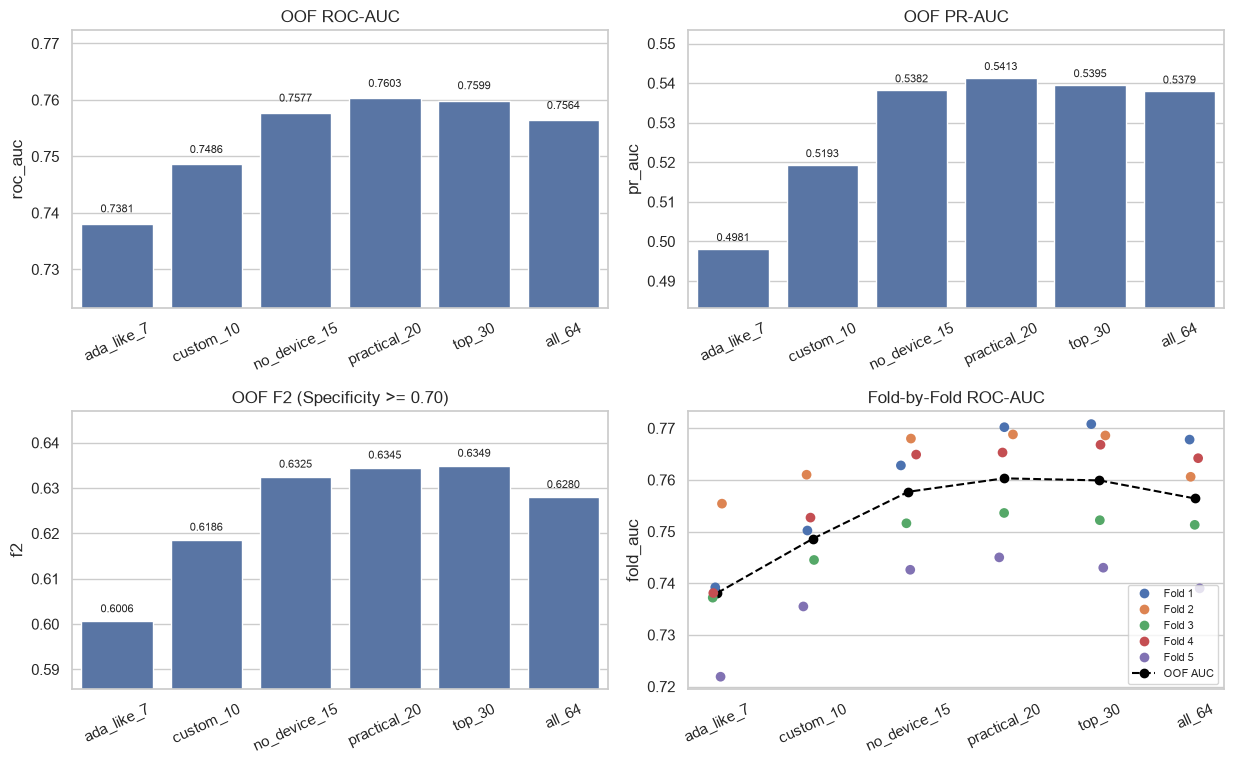

In [4]:
# plot OOF metrics and per-fold ROC-AUC across the 6 feature sets
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.8))
panels = [
    (axes[0, 0], "roc_auc", "OOF ROC-AUC"),
    (axes[0, 1], "pr_auc", "OOF PR-AUC"),
    (axes[1, 0], "f2", "OOF F2 (Specificity >= 0.70)"),
]

for ax, col, title in panels:
    sns.barplot(data=fs_df, x="feature_set", y=col, color="#4C72B0", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(fs_df[col].min() - 0.015, fs_df[col].max() + 0.012)
    for idx, val in enumerate(fs_df[col]):
        ax.text(idx, val + 0.002, f"{val:.4f}", ha="center", fontsize=8)

ax_f = axes[1, 1]
sns.stripplot(data=pd.DataFrame(fold_plot_rows), x="feature_set", y="fold_auc", hue="fold", size=7, jitter=0.1, ax=ax_f)
ax_f.plot(range(len(fs_df)), fs_df["roc_auc"], color="black", marker="o", linestyle="--", label="OOF AUC")
ax_f.set_title("Fold-by-Fold ROC-AUC")
ax_f.set_xlabel("")
ax_f.tick_params(axis="x", rotation=25)
ax_f.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

**Takeaway:** Scores improve from `ada_like_7` to `practical_20`, stay almost flat on `top_30`, and drop on `all_64` across folds. Next we tune hyperparameters on `practical_20` and `top_30`.

## 3. Hyperparameter Tuning

We test 8 settings (`n_estimators=300`) on `practical_20` and `top_30` to compare tree depth, leaf size, `max_features`, and `class_weight`.

In [5]:
# test 8 hyperparameter settings on the top 2 feature sets
grid = [
    ("d8_leaf15_sqrt",   {"n_estimators": 300, "max_depth": 8,    "min_samples_leaf": 15, "max_features": "sqrt", "class_weight": None}),
    ("d8_leaf30_f03",    {"n_estimators": 300, "max_depth": 8,    "min_samples_leaf": 30, "max_features": 0.3,    "class_weight": None}),
    ("d12_leaf15_sqrt",  {"n_estimators": 300, "max_depth": 12,   "min_samples_leaf": 15, "max_features": "sqrt", "class_weight": None}),
    ("d12_leaf15_f03",   {"n_estimators": 300, "max_depth": 12,   "min_samples_leaf": 15, "max_features": 0.3,    "class_weight": None}),
    ("d12_leaf5_sqrt",   {"n_estimators": 300, "max_depth": 12,   "min_samples_leaf": 5,  "max_features": "sqrt", "class_weight": None}),
    ("d16_leaf15_sqrt",  {"n_estimators": 300, "max_depth": 16,   "min_samples_leaf": 15, "max_features": "sqrt", "class_weight": None}),
    ("dNone_leaf30_f03", {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 30, "max_features": 0.3,    "class_weight": None}),
    ("d12_leaf15_bal",   {"n_estimators": 300, "max_depth": 12,   "min_samples_leaf": 15, "max_features": "sqrt", "class_weight": "balanced_subsample"}),
]

tune_rows = []
for set_name in ["practical_20", "top_30"]:
    cols = FEATURE_SETS[set_name]
    for cfg_name, params in grid:
        _, m, _ = run_rf_cv(cols, params)
        tune_rows.append({
            "feature_set": set_name,
            "config": cfg_name,
            "params": params,
            **m,
        })

tune_table = pd.DataFrame([
    {
        "feature_set": r["feature_set"],
        "config": r["config"],
        "max_depth": str(r["params"]["max_depth"]),
        "min_leaf": r["params"]["min_samples_leaf"],
        "max_feat": str(r["params"]["max_features"]),
        "class_weight": str(r["params"]["class_weight"]),
        "f2": r["f2"],
        "roc_auc": r["roc_auc"],
        "pr_auc": r["pr_auc"],
        "brier": r["brier"],
        "recall": r["recall"],
        "specificity": r["specificity"],
        "threshold": r["threshold"],
    }
    for r in tune_rows
]).sort_values(by=["f2", "pr_auc", "roc_auc"], ascending=False).reset_index(drop=True)

display(tune_table)

,feature_set,config,max_depth,min_leaf,max_feat,class_weight,f2,roc_auc,pr_auc,brier,recall,specificity,threshold
0,practical_20,d12_leaf15_bal,12,15,sqrt,balanced_subsample,0.6400,0.7610,0.5399,0.1925,0.6914,0.7013,0.511
1,top_30,d12_leaf15_bal,12,15,sqrt,balanced_subsample,0.6398,0.7600,0.5398,0.1926,0.6914,0.7006,0.511
2,practical_20,d8_leaf15_sqrt,8,15,sqrt,None,0.6387,0.7587,0.5401,0.1741,0.6898,0.7015,0.346
3,practical_20,dNone_leaf30_f03,None,30,0.3,None,0.6372,0.7610,0.5414,0.1726,0.6876,0.7024,0.343
4,practical_20,d16_leaf15_sqrt,16,15,sqrt,None,0.6359,0.7605,0.5409,0.1731,0.6865,0.7009,0.343
5,top_30,d12_leaf5_sqrt,12,5,sqrt,None,0.6356,0.7606,0.5412,0.1731,0.6862,0.7007,0.347
6,top_30,d8_leaf30_f03,8,30,0.3,None,0.6356,0.7595,0.5385,0.1732,0.6862,0.7004,0.347
7,top_30,d8_leaf15_sqrt,8,15,sqrt,None,0.6353,0.7576,0.5383,0.1746,0.6859,0.7003,0.348
8,practical_20,d8_leaf30_f03,8,30,0.3,None,0.6348,0.7598,0.5405,0.1730,0.6851,0.7008,0.346
9,top_30,d12_leaf15_sqrt,12,15,sqrt,None,0.6347,0.7603,0.5412,0.1733,0.6851,0.7006,0.347


**Takeaway:** `practical_20` with `d12_leaf15_bal` gets the highest F2 (0.6400) but hurts Brier score (0.1925), and `d8_leaf15_sqrt` gets 0.6387 F2 with lower ROC-AUC (0.7587). We choose `practical_20` with `dNone_leaf30_f03` because it reaches higher ROC-AUC (0.7610), higher PR-AUC (0.5414), and the best Brier score (0.1726) with strong F2 (0.6372).

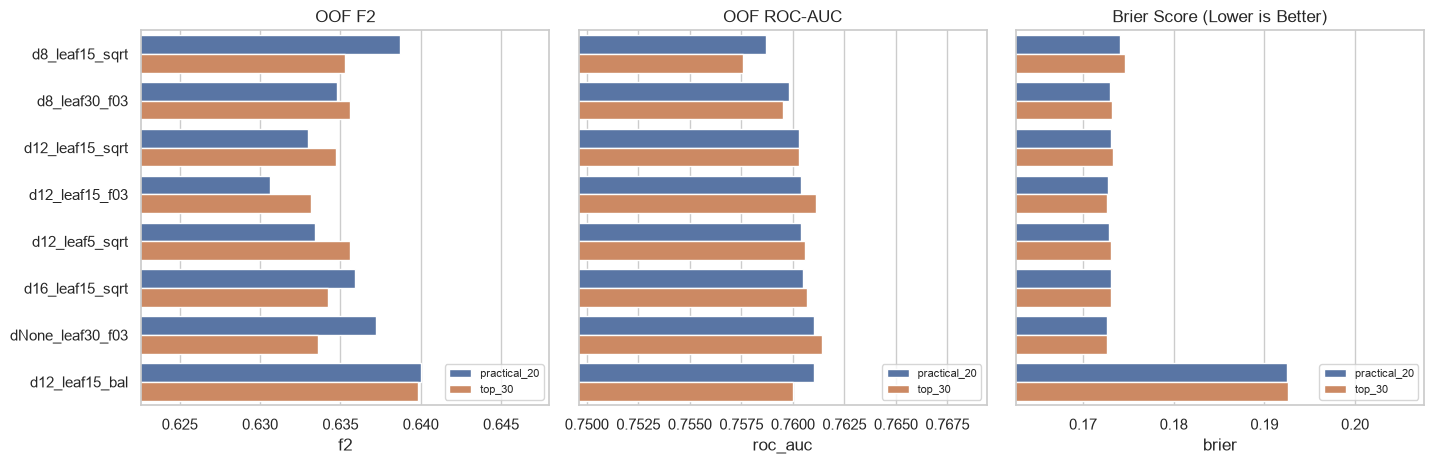

In [6]:
# compare F2, ROC-AUC, and Brier across the 8 settings
plot_tune = pd.DataFrame(tune_rows)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8), sharey=True)

sns.barplot(data=plot_tune, y="config", x="f2", hue="feature_set", ax=axes[0])
axes[0].set_title("OOF F2")
axes[0].set_xlim(plot_tune["f2"].min() - 0.008, plot_tune["f2"].max() + 0.008)
axes[0].set_ylabel("")

sns.barplot(data=plot_tune, y="config", x="roc_auc", hue="feature_set", ax=axes[1])
axes[1].set_title("OOF ROC-AUC")
axes[1].set_xlim(plot_tune["roc_auc"].min() - 0.008, plot_tune["roc_auc"].max() + 0.008)
axes[1].set_ylabel("")

sns.barplot(data=plot_tune, y="config", x="brier", hue="feature_set", ax=axes[2])
axes[2].set_title("Brier Score (Lower is Better)")
axes[2].set_xlim(plot_tune["brier"].min() - 0.01, plot_tune["brier"].max() + 0.015)
axes[2].set_ylabel("")

for ax in axes:
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway:** `practical_20` matches or beats `top_30` with 10 fewer questions, and `dNone_leaf30_f03` keeps raw probabilities well calibrated. We pick `practical_20` + `dNone_leaf30_f03` as our final model.

## 4. Calibration, Threshold, and Referral Table

### 4.1 Calibration Check

We check the Brier score and calibration curve of our chosen model (`practical_20` + `dNone_leaf30_f03`), and compare it with 3-fold Platt (`sigmoid`) scaling fitted inside each training fold.

In [7]:
# compare raw RF oof probabilities with in-fold Platt (sigmoid) calibration
best_set = "practical_20"
best_cols = FEATURE_SETS[best_set]
best_raw_cols = raw_input_cols(best_cols)
best_params = {
    "n_estimators": 300,
    "max_depth": None,
    "min_samples_leaf": 30,
    "max_features": 0.3,
    "class_weight": None,
}

best_oof = np.zeros(len(df), dtype=float)
platt_oof = np.zeros(len(df), dtype=float)

for tr, va in splits:
    X_tr, X_va = df.iloc[tr][best_raw_cols], df.iloc[va][best_raw_cols]

    pipe_raw = Pipeline([
        ("prep", preprocess.build_preprocessor("rf", best_cols, use_engineered=True)),
        ("clf", RandomForestClassifier(**best_params, n_jobs=-1, random_state=evaluate.SEED)),
    ])
    pipe_raw.fit(X_tr, y[tr])
    best_oof[va] = pipe_raw.predict_proba(X_va)[:, 1]

    pipe_base = Pipeline([
        ("prep", preprocess.build_preprocessor("rf", best_cols, use_engineered=True)),
        ("clf", RandomForestClassifier(**best_params, n_jobs=-1, random_state=evaluate.SEED)),
    ])
    cal = CalibratedClassifierCV(estimator=pipe_base, method="sigmoid", cv=3)
    cal.fit(X_tr, y[tr])
    platt_oof[va] = cal.predict_proba(X_va)[:, 1]

best_thr, best_metrics = evaluate.find_best_threshold(y, best_oof)
best_metrics["brier"] = round(float(brier_score_loss(y, best_oof)), 4)

_, platt_metrics = evaluate.find_best_threshold(y, platt_oof)
platt_metrics["brier"] = round(float(brier_score_loss(y, platt_oof)), 4)

cal_df = pd.DataFrame([
    {"model_version": "Raw RF", **best_metrics},
    {"model_version": "Platt Sigmoid RF", **platt_metrics},
])
display(cal_df[["model_version", "brier", "roc_auc", "pr_auc", "f2", "recall", "specificity", "precision", "threshold"]])

,model_version,brier,roc_auc,pr_auc,f2,recall,specificity,precision,threshold
0,Raw RF,0.1726,0.7610,0.5414,0.6372,0.6876,0.7024,0.4929,0.343
1,Platt Sigmoid RF,0.1730,0.7607,0.5412,0.6377,0.6889,0.7001,0.4914,0.316


**Takeaway:** Raw RF already has a low Brier score (0.1726), and in-fold Platt scaling gives almost the same score (0.1730), so we keep the raw RF probabilities.

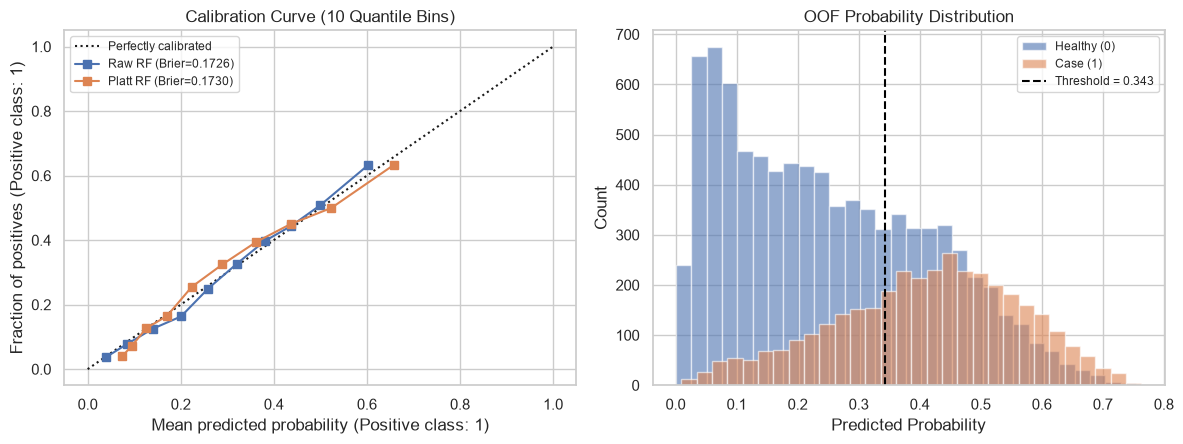

In [8]:
# plot calibration curves (10 equal-size quantile bins) and probability histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

CalibrationDisplay.from_predictions(
    y, best_oof, n_bins=10, strategy="quantile",
    name=f"Raw RF (Brier={best_metrics['brier']:.4f})", ax=axes[0],
)
CalibrationDisplay.from_predictions(
    y, platt_oof, n_bins=10, strategy="quantile",
    name=f"Platt RF (Brier={platt_metrics['brier']:.4f})", ax=axes[0],
)
axes[0].set_title("Calibration Curve (10 Quantile Bins)")
axes[0].legend(loc="upper left", fontsize=8.5)

axes[1].hist(best_oof[y == 0], bins=30, alpha=0.6, label="Healthy (0)", color="#4C72B0")
axes[1].hist(best_oof[y == 1], bins=30, alpha=0.6, label="Case (1)", color="#DD8452")
axes[1].axvline(best_thr, color="black", linestyle="--", label=f"Threshold = {best_thr:.3f}")
axes[1].set_title("OOF Probability Distribution")
axes[1].set_xlabel("Predicted Probability")
axes[1].set_ylabel("Count")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**Takeaway:** Across all 10 equal-size quantile bins, both lines stay close to the diagonal, and predicted probabilities shift higher for positive cases than for healthy adults.

### 4.2 Confusion Matrix at Best Threshold (`Specificity >= 0.70`)

Next we look at exact person counts at the selected threshold (`0.343`) and how metrics move across thresholds.

In [9]:
# build confusion matrix table and threshold trade-off plot
y_pred = (best_oof >= best_thr).astype(int)
cm = confusion_matrix(y, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

cm_table = pd.DataFrame([
    {"group": "True Negative (healthy, not referred)", "count": int(tn), "percent_of_all": round(tn / len(y) * 100, 2)},
    {"group": "False Positive (healthy, referred)", "count": int(fp), "percent_of_all": round(fp / len(y) * 100, 2)},
    {"group": "False Negative (missed cases)", "count": int(fn), "percent_of_all": round(fn / len(y) * 100, 2)},
    {"group": "True Positive (caught cases)", "count": int(tp), "percent_of_all": round(tp / len(y) * 100, 2)},
])
display(cm_table)

,group,count,percent_of_all
0,"True Negative (healthy, not referred)",6120,49.44
1,"False Positive (healthy, referred)",2593,20.95
2,False Negative (missed cases),1145,9.25
3,True Positive (caught cases),2520,20.36


**Takeaway:** Out of 12,378 adults, 6,120 healthy people avoid unnecessary tests and 2,520 undiagnosed cases are caught, while 1,145 cases are missed.

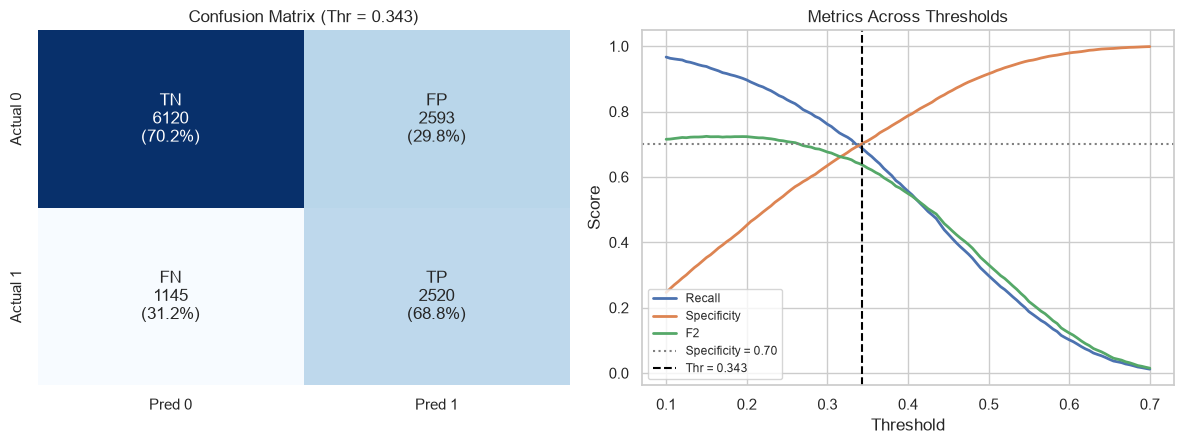

In [10]:
# plot confusion matrix heatmap and threshold curves
thrs = np.linspace(0.10, 0.70, 121)
curve_df = pd.DataFrame([evaluate.compute_metrics(y, best_oof, t) for t in thrs])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

labels = np.array([
    [f"TN\n{tn}\n({tn/(tn+fp)*100:.1f}%)", f"FP\n{fp}\n({fp/(tn+fp)*100:.1f}%)"],
    [f"FN\n{fn}\n({fn/(tp+fn)*100:.1f}%)", f"TP\n{tp}\n({tp/(tp+fn)*100:.1f}%)"],
])
sns.heatmap(
    cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"],
)
axes[0].set_title(f"Confusion Matrix (Thr = {best_thr:.3f})")

axes[1].plot(curve_df["threshold"], curve_df["recall"], label="Recall", linewidth=2)
axes[1].plot(curve_df["threshold"], curve_df["specificity"], label="Specificity", linewidth=2)
axes[1].plot(curve_df["threshold"], curve_df["f2"], label="F2", linewidth=2)
axes[1].axhline(0.70, color="gray", linestyle=":", label="Specificity = 0.70")
axes[1].axvline(best_thr, color="black", linestyle="--", label=f"Thr = {best_thr:.3f}")
axes[1].set_title("Metrics Across Thresholds")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].legend(fontsize=8.5, loc="lower left")

plt.tight_layout()
plt.show()

**Takeaway:** Threshold 0.343 reaches the highest F2 (0.6372) while keeping Specificity above 0.70 (70.24%), catching 68.76% of cases with 49.29% Precision.

### 4.3 Fixed Referral Rates (Top 20%, 30%, and 40%)

We also check what happens when a clinic can only send the top 20%, 30%, or 40% highest-risk adults for a blood test.

In [11]:
# check recall and precision at fixed 20%, 30%, and 40% referral rates
order = np.argsort(-best_oof, kind="mergesort")
referral_rows = []

for rate in [0.20, 0.30, 0.40]:
    k = int(round(rate * len(y)))
    thr_r = float(best_oof[order[k - 1]])
    m_r = evaluate.compute_metrics(y, best_oof, thr_r)
    referred = m_r["tp"] + m_r["fp"]
    referral_rows.append({
        "referral_rate": rate,
        "referred_count": int(referred),
        "actual_referral_rate": round(referred / len(y), 4),
        **m_r,
    })

referral_df = pd.DataFrame(referral_rows)
display(referral_df[["referral_rate", "threshold", "referred_count", "tp", "fn", "recall", "specificity", "precision", "f2"]])

,referral_rate,threshold,referred_count,tp,fn,recall,specificity,precision,f2
0,0.2,0.4652,2476,1413,2252,0.3855,0.8780,0.5707,0.4123
1,0.3,0.4088,3713,1962,1703,0.5353,0.7990,0.5284,0.5339
2,0.4,0.3517,4951,2453,1212,0.6693,0.7133,0.4955,0.6254


**Takeaway:** Referring the top 20% highest-risk adults catches 38.6% of all cases with 57.1% precision, and referring the top 40% catches 66.9% of all cases (2,453 of 3,665).

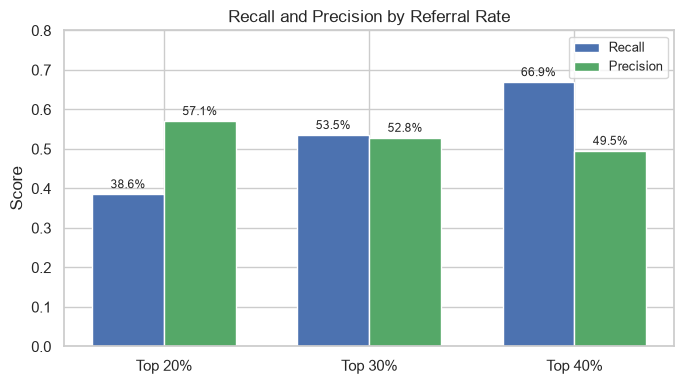

In [12]:
# bar plot of recall and precision at 20%, 30%, and 40% referral rates
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(referral_df))
w = 0.35
b1 = ax.bar(x - w/2, referral_df["recall"], width=w, label="Recall", color="#4C72B0")
b2 = ax.bar(x + w/2, referral_df["precision"], width=w, label="Precision", color="#55A868")
ax.set_xticks(x)
ax.set_xticklabels([f"Top {int(r*100)}%" for r in referral_df["referral_rate"]])
ax.set_ylim(0, 0.80)
ax.set_ylabel("Score")
ax.set_title("Recall and Precision by Referral Rate")
ax.legend(fontsize=9)

for bars in (b1, b2):
    for bar in bars:
        val = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.015, f"{val*100:.1f}%", ha="center", fontsize=8.5)

plt.tight_layout()
plt.show()

**Takeaway:** A 20% budget gives the highest hit rate per blood test (57.1%), while a 40% budget catches two-thirds of all undiagnosed cases.

## 5. Save OOF Predictions and CV Summary

Finally we save `experiments/rf_oof.csv` (in exact `train.csv` order) and `experiments/rf_cv.json` for team model comparison.

In [13]:
# save oof predictions and cv results to experiments/
exp_dir = Path("../experiments")
exp_dir.mkdir(parents=True, exist_ok=True)

oof_df = pd.DataFrame({
    "cycle": df["cycle"],
    "seqn": df["seqn"],
    "target": df["target"],
    "oof_prob": np.round(best_oof, 6),
})
oof_path = exp_dir / "rf_oof.csv"
oof_df.to_csv(oof_path, index=False)

cv_summary = {
    "model": "rf",
    "best_feature_set": best_set,
    "features": best_cols,
    "best_params": {
        **best_params,
        "random_state": evaluate.SEED,
    },
    "best_metrics": best_metrics,
    "feature_set_comparison": fs_rows,
    "tuning_results": tune_rows,
    "referral_table": referral_rows,
}

cv_path = exp_dir / "rf_cv.json"
cv_path.write_text(json.dumps(cv_summary, indent=2, allow_nan=False), encoding="utf-8")

print(f"Saved {oof_path} -> shape: {oof_df.shape}")
print(f"Saved {cv_path} -> best set: {cv_summary['best_feature_set']} | F2: {best_metrics['f2']} | AUC: {best_metrics['roc_auc']}")
display(oof_df.head())

Saved ..\experiments\rf_oof.csv -> shape: (12378, 4)
Saved ..\experiments\rf_cv.json -> best set: practical_20 | F2: 0.6372 | AUC: 0.761


,cycle,seqn,target,oof_prob
0,2011-2012,62161,0,0.045470
1,2011-2012,62169,0,0.025584
2,2011-2012,62172,0,0.206945
3,2011-2012,62176,0,0.030571
4,2011-2012,62178,1,0.633991


**Takeaway:** `experiments/rf_oof.csv` (12,378 rows) and `experiments/rf_cv.json` are saved cleanly in the shared team format.